# Santosh Sigdel — Assigned Project Notebook

**Division:** Sections 1–12 (shared by everyone) + Section 14 and Sections 15.1–15.6: ResNet50 and basic model evaluation. This part uses artifacts/functions created in Section 13 when the group combines the work.

**Important:** Sections 1–12 are intentionally included because they are the common dataset exploration, preprocessing, and DataLoader foundation required for every member. The assigned later sections are copied from the master notebook without changing the project logic.

# 1. Tree Species Classification

This project develops image classification models for identifying tree species.

The project uses transfer learning with two ResNet architectures:

- ResNet18
- ResNet50

The models will be trained, validated, tested, and evaluated using accuracy, precision, recall, F1-score, confusion matrices, and n-best classification results.

# 2. Import Libraries

In [7]:
import torch.nn as nn
import torch.optim as optim


import matplotlib.pyplot as plt

print("All libraries imported successfully")
import torch.optim as optim

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
import numpy as np
import os
import torch
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

print("All libraries imported successfully")

All libraries imported successfully
All libraries imported successfully


# 3. Define Dataset Paths

### Dataset Path

The tree dataset is stored separately from the notebook. Update `data_dir`
below to the local location of the downloaded dataset before running the notebook.

In [8]:
# Update this path to the location of the downloaded tree dataset
data_dir = r"D:\Hamk uas\Neural\Project\tree"

train_dir = os.path.join(data_dir, "train")
val_dir = os.path.join(data_dir, "val")
test_dir = os.path.join(data_dir, "test")

print("Train folder:", train_dir)
print("Validation folder:", val_dir)
print("Test folder:", test_dir)

Train folder: D:\Hamk uas\Neural\Project\tree\train
Validation folder: D:\Hamk uas\Neural\Project\tree\val
Test folder: D:\Hamk uas\Neural\Project\tree\test


# 4. Check Dataset Folders

Before loading the images, we check that the training, validation, and test folders exist at the expected locations.

The dataset is divided into three parts:

- **Training set:** used to train the machine learning model.
- **Validation set:** used to monitor the model during development and training.
- **Test set:** used for the final evaluation of the trained model.

This check helps us make sure that the dataset paths are correct before we start loading the images.

In [9]:
print("Train folder exists:", os.path.exists(train_dir))
print("Validation folder exists:", os.path.exists(val_dir))
print("Test folder exists:", os.path.exists(test_dir))

Train folder exists: True
Validation folder exists: True
Test folder exists: True


# 5. Load the Dataset

The dataset is organized into folders where each folder represents one tree species.

For example, the training folder contains separate folders for different species:

```text
train/
├── Acer palmatum/
├── Cedrus deodara/
├── Celtis sinensis/
├── Ginkgo biloba/
└── ...

In [10]:
train_data = datasets.ImageFolder(train_dir)
val_data = datasets.ImageFolder(val_dir)
test_data = datasets.ImageFolder(test_dir)

print("Dataset loaded successfully!")

Dataset loaded successfully!


# 6. Explore the Tree Species Classes

Each tree species is treated as a separate classification class.

We will now display the class names detected by PyTorch and count how many different species are included in the dataset.

This information is important because the final classification layer of our ResNet models needs one output for each tree species.

In [11]:
print("Tree species/classes:")

for i, class_name in enumerate(train_data.classes):
    print(i, ":", class_name)

print("\nNumber of classes:", len(train_data.classes))

Tree species/classes:
0 : Acer palmatum
1 : Cedrus deodara
2 : Celtis sinensis
3 : Cinnamomum camphora (Linn) Presl
4 : Elaeocarpus decipiens
5 : Flowering cherry
6 : Ginkgo biloba
7 : Koelreuteria paniculata
8 : Lagerstroemia indica
9 : Liquidambar formosana
10 : Liriodendron chinense
11 : Magnolia grandiflora L
12 : Magnolia liliflora Desr
13 : Michelia chapensis
14 : Osmanthus fragrans
15 : Photinia serratifolia
16 : Platanus
17 : Prunus cerasifera f. atropurpurea
18 : Salix babylonica
19 : Sapindus saponaria
20 : Styphnolobium japonicum
21 : Triadica sebifera
22 : Zelkova serrata

Number of classes: 23


# 7. Number of Images

Next, we check the number of images in each part of the dataset.

The training set is used to train the models, the validation set is used during model development, and the test set is kept for the final evaluation.

Knowing the number of images gives us an overview of the size of the dataset before training the models.

In [12]:
print("Number of training images:", len(train_data))
print("Number of validation images:", len(val_data))
print("Number of test images:", len(test_data))

print("\nTotal images:", len(train_data) + len(val_data) + len(test_data))

Number of training images: 3850
Number of validation images: 482
Number of test images: 472

Total images: 4804


# 8. Inspect Example Images

Before applying preprocessing techniques, we inspect several images from the training dataset.

This helps us understand the visual characteristics of the dataset and identify possible issues that could affect classification performance.

We will look for differences such as:

- Image size and aspect ratio
- Lighting conditions
- Backgrounds
- Camera viewpoint
- Tree position in the image
- Image quality
- Visual differences between tree species

These observations will help us decide which preprocessing and data augmentation techniques should be used later.

# 9. Display One Training Image

We first display one image from the training dataset together with its tree species label.

Image size: (1200, 1600)
Label number: 0
Tree species: Acer palmatum


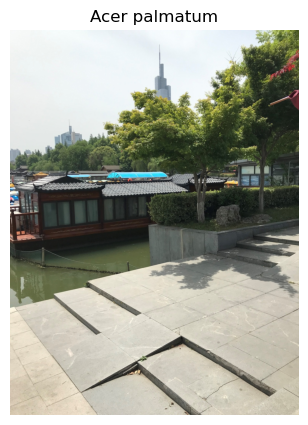

In [13]:
image, label = train_data[0] #gets the first image from the training dataset.

print("Image size:", image.size)
print("Label number:", label)
print("Tree species:", train_data.classes[label])

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.title(train_data.classes[label])
plt.axis("off")
plt.show()

# 10. Inspect the Training Images

## 10.1 Display Several Training Images

Looking at several images gives us a better understanding of the variation within the dataset.

The images may differ in viewpoint, lighting, background, and the position of the tree. These variations are important because the model needs to learn features that are related to the tree species rather than memorizing a particular image background or composition.

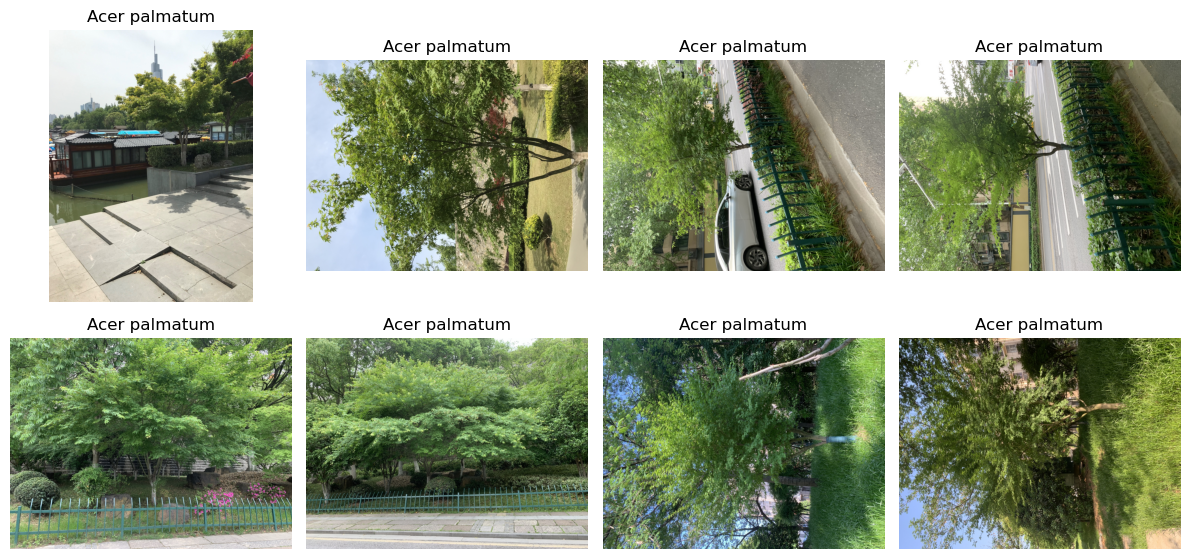

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    image, label = train_data[i]

    ax.imshow(image)
    ax.set_title(train_data.classes[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

## 10.2 Check Image Sizes

Images in a dataset may have different resolutions.

We check several images to see whether the dataset contains images with different dimensions.

This is important because the images will later need to be converted into a consistent size before they are given to the neural network.

In [15]:
for i in range(10):
    image, label = train_data[i]
    print(i, train_data.classes[label], image.size)

0 Acer palmatum (1200, 1600)
1 Acer palmatum (1600, 1200)
2 Acer palmatum (1600, 1200)
3 Acer palmatum (1600, 1200)
4 Acer palmatum (1600, 1200)
5 Acer palmatum (1600, 1200)
6 Acer palmatum (1600, 1200)
7 Acer palmatum (1600, 1200)
8 Acer palmatum (1600, 1200)
9 Acer palmatum (1600, 1200)


## 10.3 Inspect Images from Different Tree Species

The previous examples mainly came from the first class because the images in the dataset are organized by class.

To better understand the dataset, we now display one example image from each of several different tree species.

This allows us to compare the visual characteristics of different classes and identify possible differences in image orientation, background, lighting, and image composition.

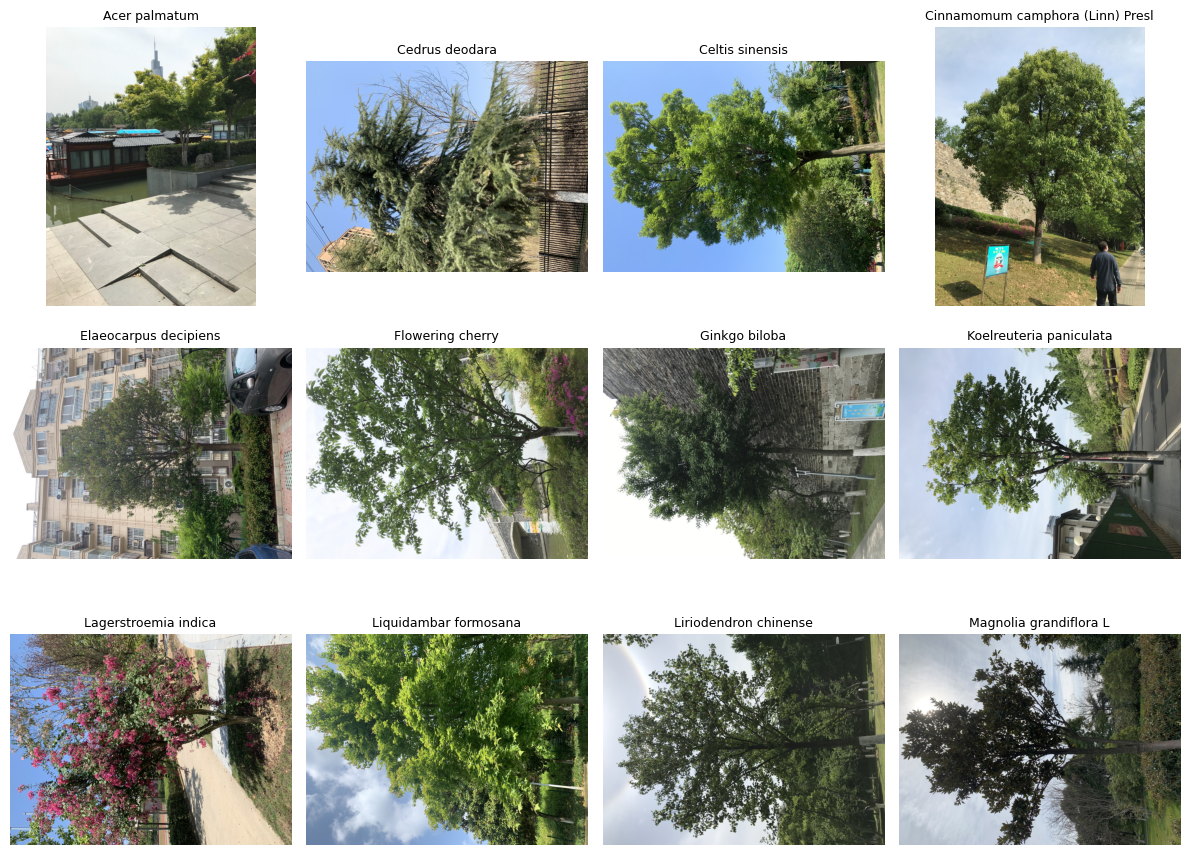

In [16]:
fig, axes = plt.subplots(3, 4, figsize=(12, 9))

# Select one image from 12 different classes
for i, ax in enumerate(axes.flat):
    class_name = train_data.classes[i]
    
    # Find the first image belonging to this class
    for image_index in range(len(train_data)):
        _, label = train_data[image_index]
        
        if label == i:
            image, _ = train_data[image_index]
            break
    
    ax.imshow(image)
    ax.set_title(class_name, fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 10.4 Investigate Image Orientation

The initial inspection showed that the dataset contains both portrait and landscape images.

Some images also appear to have different orientations. We therefore inspect the dimensions of images from different classes before deciding whether additional preprocessing is necessary.

The goal is to determine whether the variation is simply due to different aspect ratios or whether some images require orientation correction.

In [17]:
for class_index in range(10):
    class_name = train_data.classes[class_index]
    
    for image_index in range(len(train_data)):
        image, label = train_data[image_index]
        
        if label == class_index:
            print(class_name, "->", image.size)
            break

Acer palmatum -> (1200, 1600)
Cedrus deodara -> (1600, 1200)
Celtis sinensis -> (1600, 1200)
Cinnamomum camphora (Linn) Presl -> (1200, 1600)
Elaeocarpus decipiens -> (1600, 1200)
Flowering cherry -> (1600, 1200)
Ginkgo biloba -> (1600, 1200)
Koelreuteria paniculata -> (1600, 1200)
Lagerstroemia indica -> (1600, 1200)
Liquidambar formosana -> (1600, 1200)


## 10.5 Inspect Random Training Images

To avoid examining only the first images of the dataset, we also display randomly selected training images.

This gives us a more representative view of the dataset and helps identify whether image orientation, lighting, background, or quality problems occur throughout the dataset.

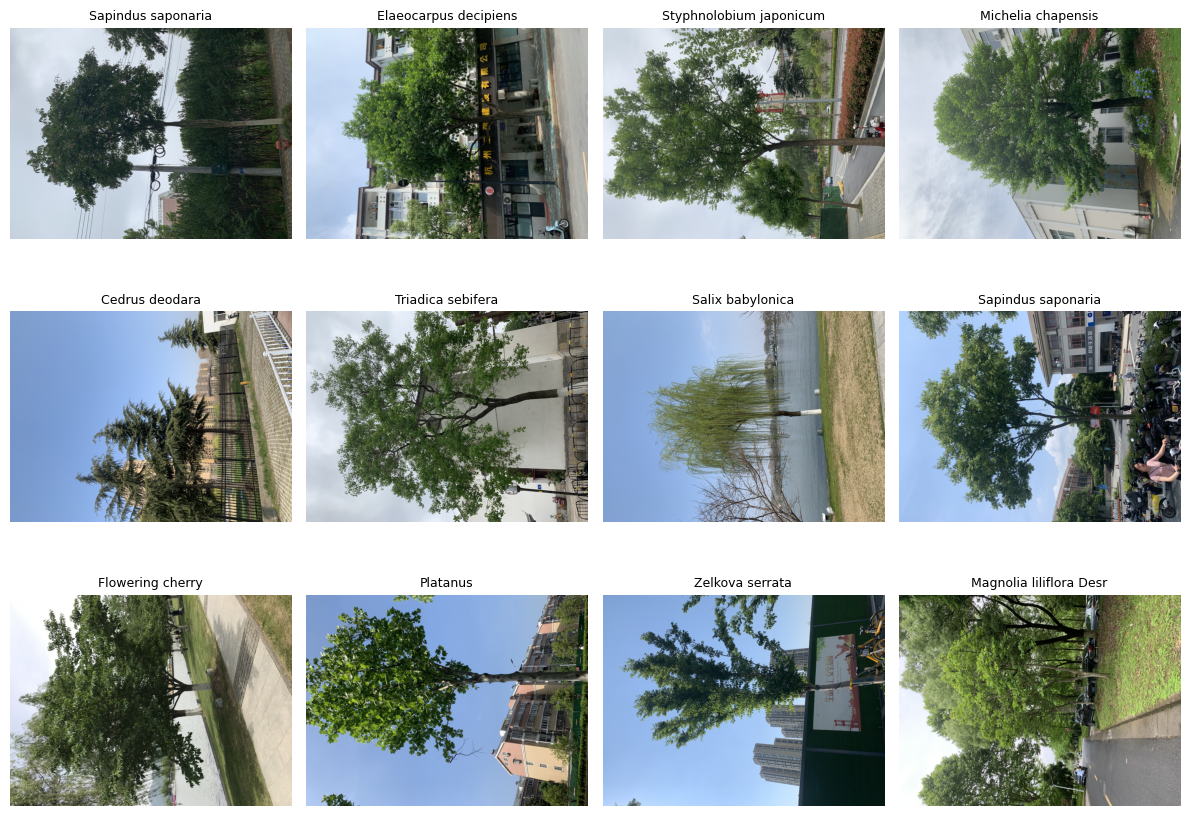

In [18]:
import random

random_indices = random.sample(range(len(train_data)), 12)

fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for ax, index in zip(axes.flat, random_indices):
    image, label = train_data[index]
    
    ax.imshow(image)
    ax.set_title(train_data.classes[label], fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 10.6 Check Image Orientation Metadata

During the image inspection, several images appeared to be rotated.

Before applying any rotation manually, we check whether the images contain EXIF orientation information.

EXIF metadata can contain information about how an image should be displayed. If this information is present, it can be corrected when the image is loaded.

This helps us avoid unnecessarily modifying images that are already stored correctly.

In [19]:
%pip install Pillow

from PIL import Image

image, label = train_data[0]

print("Image:", train_data.classes[label])
print("Image size:", image.size)

exif = image.getexif()

if 274 in exif:
    print("EXIF orientation:", exif[274])
else:
    print("No EXIF orientation information found.")

Note: you may need to restart the kernel to use updated packages.
Image: Acer palmatum
Image size: (1200, 1600)
No EXIF orientation information found.


## 10.7 Check Class Distribution

The dataset contains 23 different tree species.

Before training the models, we check how many images are available for each species.

This helps us identify whether the dataset is reasonably balanced or whether some tree species have significantly more images than others.

Class imbalance can affect model performance because a model may have more opportunities to learn classes with a larger number of training 

In [20]:
from collections import Counter

class_counts = Counter(train_data.targets)

print("Training images per class:\n")

for class_index, count in class_counts.items():
    print(train_data.classes[class_index], ":", count)

Training images per class:

Acer palmatum : 162
Cedrus deodara : 125
Celtis sinensis : 188
Cinnamomum camphora (Linn) Presl : 234
Elaeocarpus decipiens : 172
Flowering cherry : 106
Ginkgo biloba : 228
Koelreuteria paniculata : 223
Lagerstroemia indica : 65
Liquidambar formosana : 168
Liriodendron chinense : 182
Magnolia grandiflora L : 212
Magnolia liliflora Desr : 190
Michelia chapensis : 154
Osmanthus fragrans : 173
Photinia serratifolia : 120
Platanus : 193
Prunus cerasifera f. atropurpurea : 99
Salix babylonica : 136
Sapindus saponaria : 224
Styphnolobium japonicum : 157
Triadica sebifera : 154
Zelkova serrata : 185


## 10.8 Visualize the Class Distribution

A bar chart makes it easier to see whether some tree species have substantially more training images than others.

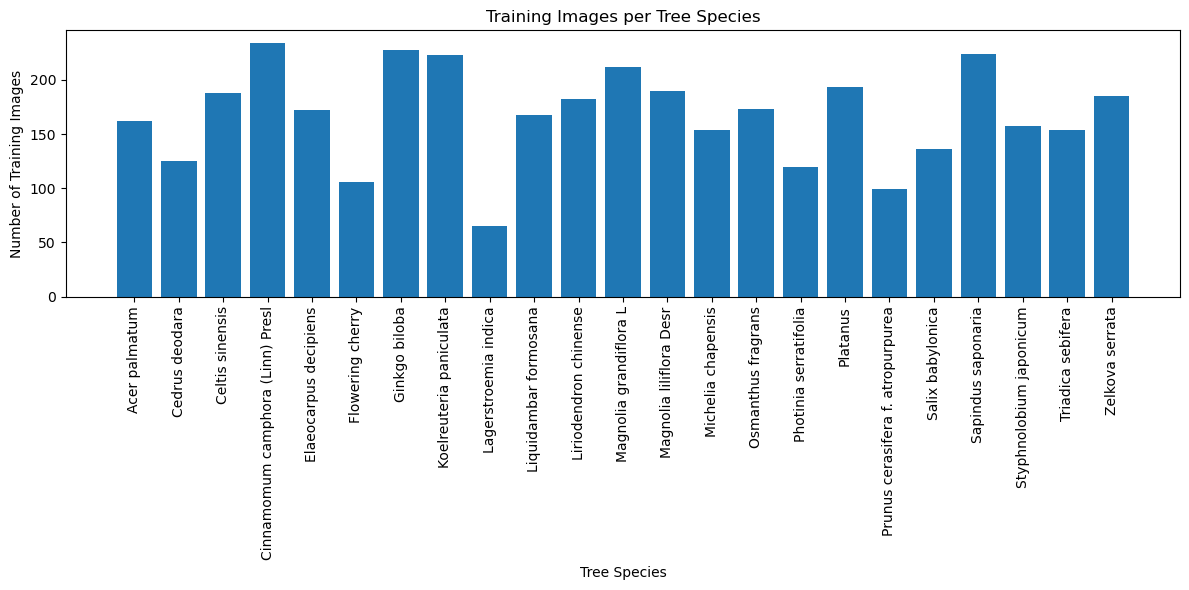

In [21]:
plt.figure(figsize=(12, 6))

plt.bar(
    train_data.classes,
    [class_counts[i] for i in range(len(train_data.classes))]
)

plt.xlabel("Tree Species")
plt.ylabel("Number of Training Images")
plt.title("Training Images per Tree Species")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

# 11. Image Preprocessing

The dataset contains images with different resolutions and orientations. Before training the neural networks, the images need to be converted into a consistent format.

Because we are using pretrained ResNet models, the images will be processed using a format suitable for ImageNet-pretrained networks.

For the training data, we use data augmentation to introduce some variation into the images. This can help the model generalize better to images that it has not seen during training.

The validation and test images are only resized and normalized. Random augmentation is not applied to these datasets because they should provide a consistent evaluation of the models.

The preprocessing steps are:

- Resize and crop images to 224 × 224 pixels.
- Apply small random rotations during training.
- Apply random horizontal flipping during training.
- Convert images to PyTorch tensors.
- Normalize the images using the standard ImageNet mean and standard deviation.

## 11.1 Training Transformations

The training images use data augmentation because the dataset contains trees photographed from different viewpoints and under different conditions.

A small random rotation is used because the dataset contains images with different orientations. A horizontal flip is also used to create additional variation.

We use moderate transformations rather than strong transformations because excessive changes could make the tree species harder to recogniz

In [22]:
train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10, fill=(128, 128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Training transformations created successfully!")

Training transformations created successfully!


## 11.2 Validation and Test Transformations

The validation and test datasets should not use random augmentation.

We want the models to be evaluated using a consistent preprocessing procedure.

Therefore, validation and test images are resized, converted to tensors, and normalized using the same ImageNet normalization values.

In [23]:
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

## 11.3 Create Transformed Datasets

We now apply the training transformations to the training dataset and the evaluation transformations to the validation and test datasets.

The original datasets used above were useful for inspecting the images. These new datasets will be used for training and evaluation.

In [24]:
train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    val_dir,
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=eval_transform
)

print("Transformed datasets created successfully!")

Transformed datasets created successfully!


## 11.4 Check a Preprocessed Image

We display one transformed image to verify that the preprocessing pipeline works correctly.

Because the image has been normalized, its pixel values are no longer directly suitable for normal display. Therefore, we reverse the normalization before displaying it.

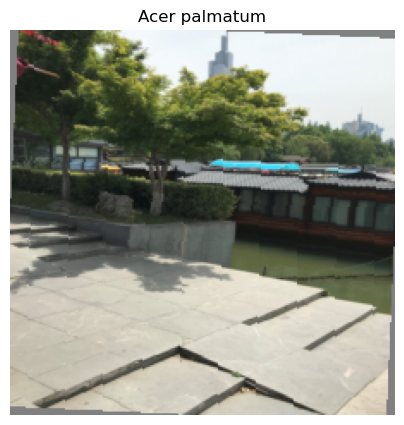

Processed image shape: torch.Size([3, 224, 224])


In [25]:
image, label = train_dataset[0]

# Reverse ImageNet normalization for display
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

image_display = image.numpy().transpose(1, 2, 0)
image_display = image_display * std + mean
image_display = np.clip(image_display, 0, 1)

plt.figure(figsize=(5, 5))
plt.imshow(image_display)
plt.title(train_dataset.classes[label])
plt.axis("off")
plt.show()

print("Processed image shape:", image.shape)

# 12. Create DataLoaders

The datasets contain thousands of images, so we do not send all images to the neural network at the same time.

PyTorch DataLoader divides the dataset into smaller batches.

We use a batch size of 32. During training, the training images are shuffled so that the model does not always see the images in the same order.

The validation and test datasets are not shuffled because their purpose is evaluation, where a consistent order is sufficient.

In [26]:
batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("DataLoaders created successfully!")

DataLoaders created successfully!


## 12.1 Check One Training Batch

Before starting model training, we check one batch from the training DataLoader.

The expected image tensor shape is:

`[batch size, channels, height, width]`

For our project this should be approximately:

`[32, 3, 224, 224]`

In [27]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("First few labels:", labels[:10])

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
First few labels: tensor([ 1, 19,  7,  4,  0,  1, 19,  6, 21, 13])


## 12.2 Display a Training Batch

We display several images from one training batch to confirm that the DataLoader is providing correctly transformed images and their corresponding tree species labels.

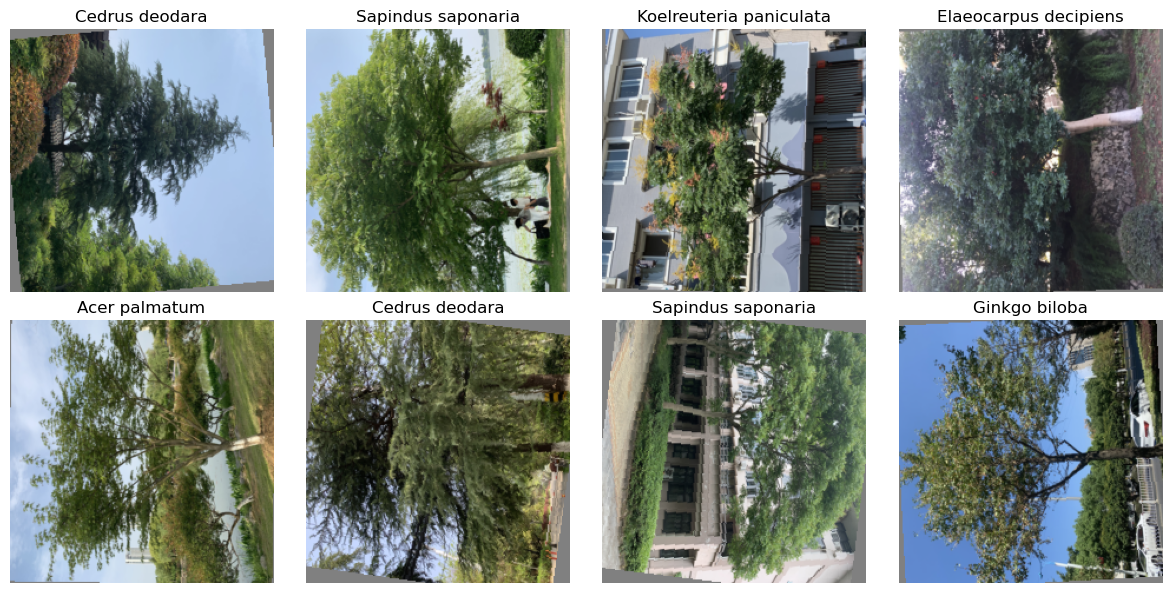

In [28]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

for i, ax in enumerate(axes.flat):

    image = images[i].numpy().transpose(1, 2, 0)

    # Reverse normalization for display
    image = image * std + mean
    image = np.clip(image, 0, 1)

    ax.imshow(image)
    ax.set_title(train_dataset.classes[labels[i]])
    ax.axis("off")

plt.tight_layout()
plt.show()

# 14. ResNet50 Model Development and Training

In [41]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


## 14.1 Load the Pretrained ResNet50 Model

ResNet50 is the second transfer learning architecture used in this project.

Like ResNet18, ResNet50 is a convolutional neural network that was pretrained on the ImageNet dataset.

Instead of training the complete network from the beginning, we use the pretrained model and replace its final classification layer so that it can classify the 23 tree species in our dataset.

In [35]:
# Load pretrained ResNet50

model50 = models.resnet50(weights="IMAGENET1K_V2")

print("ResNet50 loaded successfully")

ResNet50 loaded successfully


## 14.2 Inspect the Original ResNet50 Classification Layer

The pretrained ResNet50 model was originally trained on ImageNet, which contains 1000 classes.

Our tree dataset contains only 23 classes.

Before replacing the final layer, we inspect the original classification layer to understand its structure.

In [36]:
print("Original ResNet50 final layer:")
print(model50.fc)

Original ResNet50 final layer:
Linear(in_features=2048, out_features=1000, bias=True)


## 14.3 Adapt ResNet50 for the Tree Dataset

The original ResNet50 classification layer produces 1000 outputs because it was trained on ImageNet.

Our dataset contains 23 tree species.

Therefore, we replace the original classification layer with a new fully connected layer containing 23 outputs.

Each output corresponds to one tree species in our dataset.

In [42]:
# Number of tree species
num_classes = len(train_dataset.classes)

print("Number of classes:", num_classes)

# Replace the final classification layer
model50.fc = nn.Linear(
    model50.fc.in_features,
    num_classes
)
# Move model to selected device
model50 = model50.to(device)

print("New ResNet50 final layer:")
print(model50.fc)

Number of classes: 23
New ResNet50 final layer:
Linear(in_features=2048, out_features=23, bias=True)


## 14.4 Set Loss Function and Optimizer

We use cross-entropy loss for the 23-class tree species classification problem.

The Adam optimizer is used to update the ResNet50 model parameters during training.

In [39]:
# Loss function
criterion50 = nn.CrossEntropyLoss()

# Optimizer for ResNet50
optimizer50 = optim.Adam(
    model50.parameters(),
    lr=0.0001
)

print("Loss function and optimizer created successfully.")

Loss function and optimizer created successfully.


In [44]:
def train_model_best(model, train_loader, val_loader, criterion, optimizer, epochs, save_path):
    train_losses, val_losses, train_accs, val_accs = [], [], [], []
    best_acc = 0

    for epoch in range(epochs):
        # train
        model.train()
        loss_sum, correct, total = 0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            total += len(y)
        train_losses.append(loss_sum / total)
        train_accs.append(100 * correct / total)

        # validate
        model.eval()
        loss_sum, correct, total = 0, 0, 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                out = model(x)
                loss_sum += criterion(out, y).item() * len(y)
                correct += (out.argmax(1) == y).sum().item()
                total += len(y)
        val_losses.append(loss_sum / total)
        val_accs.append(100 * correct / total)

        # save best
        if val_accs[-1] > best_acc:
            best_acc = val_accs[-1]
            torch.save(model.state_dict(), save_path)

        print(f"Epoch {epoch+1}/{epochs}  Train Acc: {train_accs[-1]:.2f}%  Val Acc: {val_accs[-1]:.2f}%")

    return train_losses, val_losses, train_accs, val_accs

## 14.5 Final ResNet50 Training

The ResNet50 model is trained for five epochs using the training dataset.

The validation dataset is used to monitor model performance during training.

The model with the highest validation accuracy is saved as `resnet50_best.pth`.

In [45]:
# Number of epochs for final ResNet50 training
epochs50 = 5

# Train ResNet50 and save the best validation model
train_losses50, val_losses50, train_accuracies50, val_accuracies50 = train_model_best(
    model50,
    train_loader,
    val_loader,
    criterion50,
    optimizer50,
    epochs50,
    "resnet50_best.pth"
)

Epoch 1/5  Train Acc: 34.49%  Val Acc: 65.77%
Epoch 2/5  Train Acc: 75.14%  Val Acc: 87.14%
Epoch 3/5  Train Acc: 88.94%  Val Acc: 91.91%
Epoch 4/5  Train Acc: 93.35%  Val Acc: 91.70%
Epoch 5/5  Train Acc: 96.03%  Val Acc: 94.19%


## 14.6 Visualize ResNet50 Training Results

The training and validation loss and accuracy are plotted to evaluate how the ResNet50 model learned during training.

These plots help us compare the training and validation performance across epochs and identify possible overfitting or underfitting.

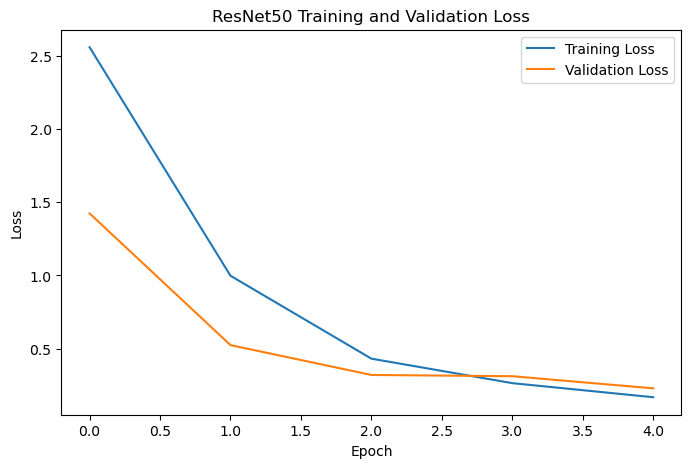

In [46]:
plt.figure(figsize=(8, 5))

plt.plot(train_losses50, label="Training Loss")
plt.plot(val_losses50, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet50 Training and Validation Loss")
plt.legend()
plt.show()

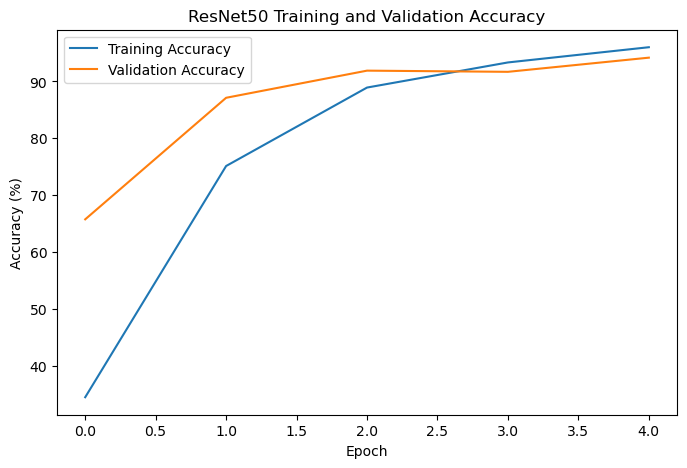

In [47]:
plt.figure(figsize=(8, 5))

plt.plot(train_accuracies50, label="Training Accuracy")
plt.plot(val_accuracies50, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("ResNet50 Training and Validation Accuracy")
plt.legend()
plt.show()

# 15. Model Testing and Evaluation

The trained ResNet18 and ResNet50 models are now evaluated using the test dataset.

The test dataset was not used during model training or validation. It is used only for the final evaluation of the models.

The evaluation will include:
- Accuracy
- Precision
- Recall
- F1-score
- Confusion matrix
- n-best classification results

The same test dataset is used for both models so that their performance can be compared fairly.

In [50]:
# ---- Needed from Section 13 ----
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

def train_model_best(model, train_loader, val_loader, criterion, optimizer, epochs, save_path):
    train_losses, val_losses, train_accuracies, val_accuracies = [], [], [], []
    best_val_acc = 0.0

    for epoch in range(epochs):
        # Training
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
        train_loss = running_loss / total
        train_acc = 100 * correct / total

        # Validation
        model.eval()
        running_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                running_loss += loss.item() * images.size(0)
                correct += (outputs.argmax(1) == labels).sum().item()
                total += labels.size(0)
        val_loss = running_loss / total
        val_acc = 100 * correct / total

        train_losses.append(train_loss)
        val_losses.append(val_loss)
        train_accuracies.append(train_acc)
        val_accuracies.append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), save_path)
            print(f"Best model saved to {save_path}")

        print(f"Epoch [{epoch+1}/{epochs}] Train Loss: {train_loss:.4f} Train Accuracy: {train_acc:.2f}% "
              f"Val Loss: {val_loss:.4f} Val Accuracy: {val_acc:.2f}%")

    print("Best validation accuracy:", best_val_acc)
    return train_losses, val_losses, train_accuracies, val_accuracies

# ResNet18 structure (needed to load resnet18_best.pth in Section 15)
model18 = models.resnet18(weights="IMAGENET1K_V1")
model18.fc = nn.Linear(model18.fc.in_features, len(train_dataset.classes))
model18 = model18.to(device)

Using device: cpu


## 15.1 Prepare the Trained Models for Testing

The best model saved during training is loaded before performing the final evaluation.

In [51]:
import torch

# Load the best ResNet18 model
model18.load_state_dict(torch.load("resnet18_best.pth", map_location=device))
model18 = model18.to(device)
model18.eval()

# Load the best ResNet50 model
model50.load_state_dict(torch.load("resnet50_best.pth", map_location=device))
model50 = model50.to(device)
model50.eval()
print("Test folder exists:", os.path.exists(test_dir))


Test folder exists: True


## 15.2 Evaluate Model Predictions on the Test Dataset

A common evaluation function is used for both ResNet18 and ResNet50.

The function collects the predicted class and the true class for every image in the test dataset. These predictions will later be used to calculate the evaluation metrics and confusion matrices.

In [52]:
def get_predictions(model, data_loader):
    model.eval()

    all_labels = []
    all_predictions = []
    all_probabilities = []

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            probabilities = torch.softmax(outputs, dim=1)

            predictions = torch.argmax(outputs, dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())
            all_probabilities.extend(probabilities.cpu().numpy())

    return (
        np.array(all_labels),
        np.array(all_predictions),
        np.array(all_probabilities)
    )

In [53]:
# Get ResNet18 predictions
y_true18, y_pred18, y_prob18 = get_predictions(
    model18,
    test_loader
)

# Get ResNet50 predictions
y_true50, y_pred50, y_prob50 = get_predictions(
    model50,
    test_loader
)

print("ResNet18 predictions collected:", len(y_pred18))
print("ResNet50 predictions collected:", len(y_pred50))

ResNet18 predictions collected: 472
ResNet50 predictions collected: 472


## 15.3 Calculate Accuracy, Precision, Recall and F1-score
The predictions from the test dataset are used to calculate the main classification metrics for both ResNet18 and ResNet50.

The following metrics are calculated:

- Accuracy
- Precision
- Recall
- F1-score

Macro averaging is used for precision, recall, and F1-score so that each tree species contributes equally to the overall result.

In [54]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# ResNet18 metrics
accuracy18 = accuracy_score(y_true18, y_pred18)
precision18 = precision_score(
    y_true18,
    y_pred18,
    average="macro",
    zero_division=0
)
recall18 = recall_score(
    y_true18,
    y_pred18,
    average="macro",
    zero_division=0
)
f1_18 = f1_score(
    y_true18,
    y_pred18,
    average="macro",
    zero_division=0
)

# ResNet50 metrics
accuracy50 = accuracy_score(y_true50, y_pred50)
precision50 = precision_score(
    y_true50,
    y_pred50,
    average="macro",
    zero_division=0
)
recall50 = recall_score(
    y_true50,
    y_pred50,
    average="macro",
    zero_division=0
)
f1_50 = f1_score(
    y_true50,
    y_pred50,
    average="macro",
    zero_division=0
)

print("ResNet18 Test Results")
print("---------------------")
print(f"Accuracy : {accuracy18:.4f}")
print(f"Precision: {precision18:.4f}")
print(f"Recall   : {recall18:.4f}")
print(f"F1-score : {f1_18:.4f}")

print("\nResNet50 Test Results")
print("---------------------")
print(f"Accuracy : {accuracy50:.4f}")
print(f"Precision: {precision50:.4f}")
print(f"Recall   : {recall50:.4f}")
print(f"F1-score : {f1_50:.4f}")

ResNet18 Test Results
---------------------
Accuracy : 0.8517
Precision: 0.8966
Recall   : 0.8604
F1-score : 0.8658

ResNet50 Test Results
---------------------
Accuracy : 0.9174
Precision: 0.9321
Recall   : 0.9157
F1-score : 0.9211


## 15.4 Confusion Matrix for ResNet18

The confusion matrix shows how the ResNet18 model classified each tree species.

Each row represents the true tree species, while each column represents the predicted species.

The diagonal values represent correctly classified images. 
Values outside the diagonal show which tree species were confused with each other.

This helps us identify specific classes where the model has difficulty distinguishing between similar tree species.

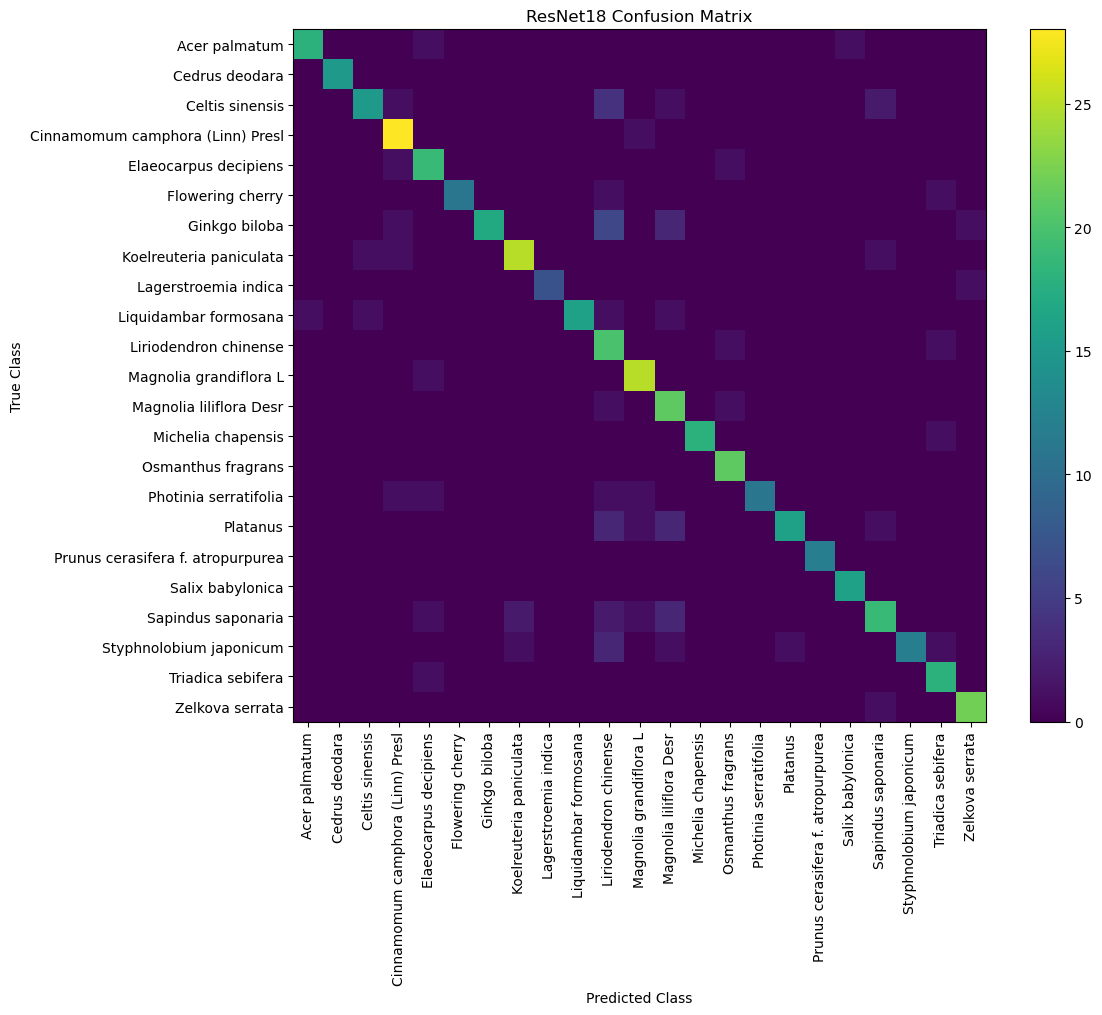

In [55]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

# Calculate confusion matrix for ResNet18
cm18 = confusion_matrix(y_true18, y_pred18)

# Plot confusion matrix
plt.figure(figsize=(12, 10))

plt.imshow(cm18, interpolation="nearest")
plt.title("ResNet18 Confusion Matrix")
plt.colorbar()

# Class names
class_names = test_dataset.classes

plt.xticks(
    np.arange(len(class_names)),
    class_names,
    rotation=90
)

plt.yticks(
    np.arange(len(class_names)),
    class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.tight_layout()
plt.show()

## 15.5 Confusion Matrix for ResNet50

The same confusion matrix analysis is performed for ResNet50.

The confusion matrix allows us to see which tree species are correctly identified and which species are frequently confused with one another.

This result will later be compared with the ResNet18 confusion matrix.

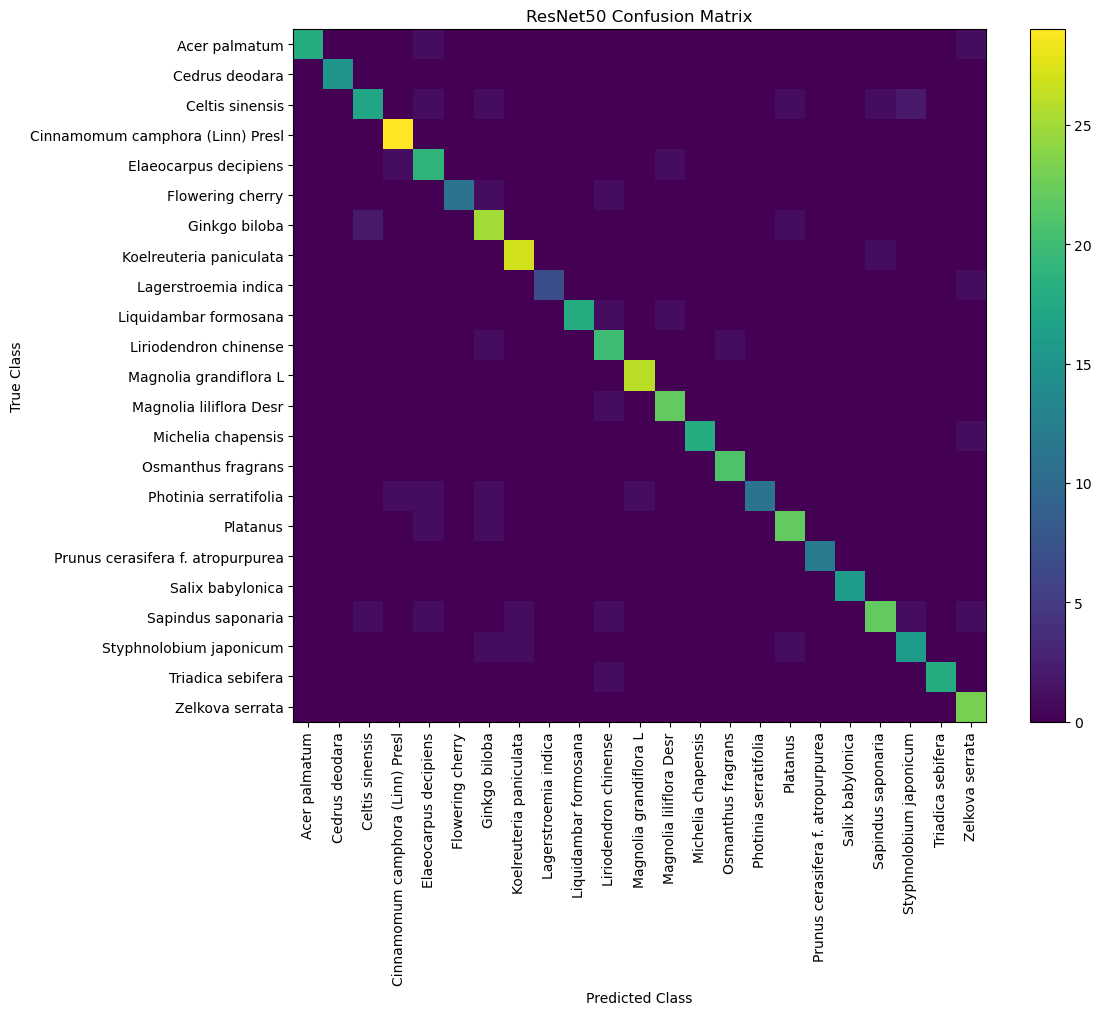

In [56]:
# Calculate confusion matrix for ResNet50
cm50 = confusion_matrix(y_true50, y_pred50)

# Plot confusion matrix
plt.figure(figsize=(12, 10))

plt.imshow(cm50, interpolation="nearest")
plt.title("ResNet50 Confusion Matrix")
plt.colorbar()

plt.xticks(
    np.arange(len(class_names)),
    class_names,
    rotation=90
)

plt.yticks(
    np.arange(len(class_names)),
    class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.tight_layout()
plt.show()

## 15.6 Comparison of Confusion Matrices

The two confusion matrices are compared to identify differences in classification behaviour between ResNet18 and ResNet50.

In particular, we look for tree species that are frequently confused by one model but correctly classified by the other.

These differences can provide information about which species are difficult to distinguish based on their visual characteristics.

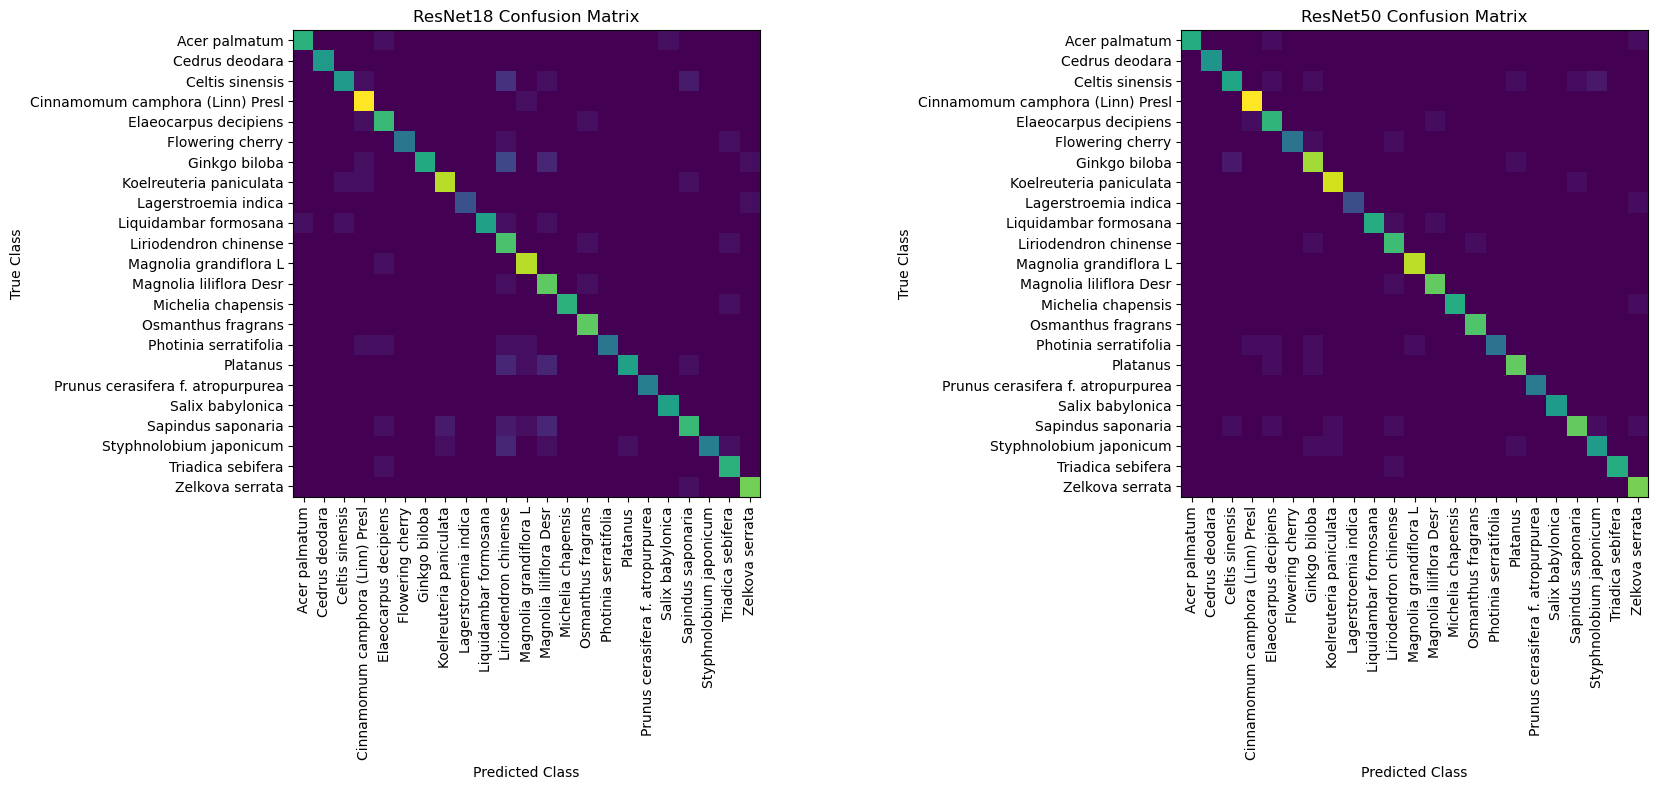

In [57]:
# Display both confusion matrices side by side

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

axes[0].imshow(cm18, interpolation="nearest")
axes[0].set_title("ResNet18 Confusion Matrix")
axes[0].set_xlabel("Predicted Class")
axes[0].set_ylabel("True Class")
axes[0].set_xticks(np.arange(len(class_names)))
axes[0].set_yticks(np.arange(len(class_names)))
axes[0].set_xticklabels(class_names, rotation=90)
axes[0].set_yticklabels(class_names)

axes[1].imshow(cm50, interpolation="nearest")
axes[1].set_title("ResNet50 Confusion Matrix")
axes[1].set_xlabel("Predicted Class")
axes[1].set_ylabel("True Class")
axes[1].set_xticks(np.arange(len(class_names)))
axes[1].set_yticks(np.arange(len(class_names)))
axes[1].set_xticklabels(class_names, rotation=90)
axes[1].set_yticklabels(class_names)

plt.tight_layout()
plt.show()